![Banner](../images/09_09_banner_rs_image_classification.png)


# Classical Image Classification: Pixel-Based and Object-Based

This notebook maps land cover and crop type in the **U.S.


## Overview

Corn Belt** (north-central Iowa) from a
**single mid-season Landsat scene** (15 July 2025) and the **2025 USDA Cropland Data Layer (CDL)**
used as labelled data. Everything is done with **GeoLattice** (`geolattice.rsense`): reading and scaling
Landsat Collection 2 data, quality masking, spectral indices, spatial train/validation/test splits,
unsupervised and supervised classifiers, segmentation and object-based image analysis (OBIA).

Two ways of defining the unit of classification are compared:

| Approach | Unit | Methods in this notebook |
|---|---|---|
| **Pixel-based** | One 30 m pixel and its eight predictors | k-means (unsupervised), Random Forest, SVM, XGBoost |
| **Object-based (OBIA)** | A segment (superpixel) described by band statistics and shape | SLIC segmentation + Random Forest / XGBoost |

> **About the scene.** The mid-season acquisition of 2025 available in `Landsat_9/` is
> `LC08_L2SP_027030_20250715` (the folder is named *Landsat_9*, but this scene was acquired by
> Landsat 8; the only 2025 Landsat 9 scene, 4 May, is too early in the season). Landsat 8 OLI and
> Landsat 9 OLI-2 share the same bands, 30 m grid and Collection 2 processing, so the workflow is
> identical for either. The image and the CDL labels are from the **same growing season**.


## Core concepts

### Learning objectives

1. Load, scale and quality-mask Landsat Collection 2 Level-2 data with GeoLattice.
2. Align a categorical reference raster (CDL) to the image grid and group its classes.
3. Build predictors (six reflective bands plus NDVI and NDMI).
4. Split labelled pixels into **train / validation / test** sets using spatial blocks.
5. Compare k-means, Random Forest, SVM and XGBoost, and choose a model on the validation set.
6. Segment an image, compute object features and classify objects (OBIA).
7. Evaluate every method on the **same held-out test pixels**.

### Contents

1. Setup
2. Landsat data: scale, mask, indices
3. CDL 2025 reference labels
4. Train / validation / test split
5. Pixel-based classification
6. Final evaluation and map
7. Object-based classification (OBIA)
8. Pixel vs. object comparison
9. Summary and exercises


## Setup

The notebook imports GeoLattice and the standard scientific stack:

- `geolattice.rsense` (`rs`): raster input/output, Landsat scaling and QA masks, spectral indices and the
  compute backend.
- `geolattice.rsense.classify.image_classification` (`ic`): label sampling, spatial splits, unsupervised and
  supervised classifiers, maps and accuracy reports.
- `geolattice.rsense.classify.obia`: segmentation and per-object features.

`rs.set_backend("cpu")` keeps every array on the CPU so the notebook behaves identically on machines
with and without a GPU. `SEED` makes the sampling, splits and models reproducible.

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # control warning messages
warnings.filterwarnings("ignore", category=UserWarning)  # hide user warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)  # hide numeric warnings (e.g. NaN means)
warnings.filterwarnings("ignore", category=FutureWarning)  # hide deprecation notices

import json  # read the scene metadata
from pathlib import Path  # file paths

import numpy as np  # arrays
import pandas as pd  # tables
import xarray as xr  # labelled rasters
import rasterio  # raster reading
import matplotlib.pyplot as plt  # figures
from matplotlib.colors import ListedColormap  # class colours
from matplotlib.patches import Patch  # legend patches
from rasterio.enums import Resampling  # resampling methods
from skimage.segmentation import mark_boundaries  # draw segment outlines

import geolattice.rsense as rs  # GeoLattice remote sensing
from geolattice.rsense.classify import image_classification as ic  # GeoLattice image-classification module
from geolattice.rsense.classify import obia  # GeoLattice object-based (OBIA) tools

rasterio.Env(CPL_LOG="/dev/null").__enter__()   # silence GDAL log messages
plt.rcParams.update({"figure.dpi": 110})  # figure resolution
SEED = 42  # random seed
print("geolattice.rsense", rs.__version__, "| backend:", rs.set_backend("cpu"))  # GeoLattice version and compute backend

geolattice.rsense 0.2.0.dev0 | backend: cpu


### Locate the data

The cell finds the `Corn_belt` data folder whether Jupyter was started in this notebook's folder or in the
repository root, then defines the three inputs: the 15 July 2025 Landsat scene, the 2025 30 m CDL
(labels) and the study-area polygon. A clear error is raised if a file is missing. `request.json`
stored with the scene records which satellite acquired it; it is printed so the platform is visible.


In [2]:
# Resolve the data folder for both common working directories
CANDIDATES = [Path("../../../../Data/08_remote_sensing/08_09_image_classification/Corn_belt"),
              Path("Data/08_remote_sensing/08_09_image_classification/Corn_belt")]
DATA = next((p for p in CANDIDATES if p.is_dir()), None)  # the first candidate that exists
if DATA is None:  # neither found
    # stop with a clear message
    raise FileNotFoundError("Run Jupyter from this notebook's folder or from the GeoLattice repository root.")

SCENE_DIR = DATA / "Landsat_9" / "2025_07_LC08_L2SP_027030_20250715_02_T1"   # mid-season 2025
CDL_PATH = DATA / "CDL" / "30_m" / "CDL_2025_30m.tif"                         # 2025 labels
AOI_PATH = DATA / "aoi.geojson"  # the study-area polygon
for p in (SCENE_DIR, CDL_PATH, AOI_PATH):  # every input ...
    if not p.exists():  # ... must exist
        raise FileNotFoundError(p)  # stop if one is missing

# metadata of the downloaded Landsat scene
scene = json.loads((SCENE_DIR / "request.json").read_text())["scenes"][0]
# scene id, platform, date and cloud cover
print(f"Scene {scene['id']} | {scene['platform']} | {scene['datetime'][:10]} | cloud {scene['cloud']}%")


Scene LC08_L2SP_027030_20250715_02_T1 | landsat-8 | 2025-07-15 | cloud 3.66%


## Landsat data: scale, mask, indices

### Read the raw bands

`rs.read` returns each GeoTIFF as a georeferenced `xarray.DataArray`. With `masked=False` the stored
integer **digital numbers (DN)** are kept untouched, because the next step converts them correctly. The
six reflective bands (blue to SWIR2) and `qa_pixel` are combined into one `xarray.Dataset`. The
`pyrsense:sensor` attribute tells GeoLattice which scaling rules to apply.


In [3]:
BANDS = ["blue", "green", "red", "nir", "swir16", "swir22"]  # the six reflective bands used as predictors

# One DataArray per band, squeezed from (band, y, x) to (y, x); qa_pixel is read for masking
dn = xr.Dataset({b: rs.read(SCENE_DIR / f"{b}.tif", masked=False).squeeze("band", drop=True)
                 for b in BANDS + ["qa_pixel"]})
dn = dn.rio.write_crs(dn["red"].rio.crs)  # attach the CRS
dn.attrs["pyrsense:sensor"] = "landsat"  # record the sensor for GeoLattice

# size, pixel size and CRS
print(f"{dn.rio.width} x {dn.rio.height} pixels at {abs(dn.rio.resolution()[0]):.0f} m | CRS {dn.rio.crs}")
w, s, e, n = dn.rio.transform_bounds("EPSG:4326")  # scene bounds in longitude and latitude
print(f"Scene bounds (lon/lat): {w:.3f}, {s:.3f}, {e:.3f}, {n:.3f}")  # report them

1011 x 971 pixels at 30 m | CRS EPSG:32615
Scene bounds (lon/lat): -94.088, 42.790, -93.712, 43.055


### Scale to reflectance and mask clouds

`rs.optical.scale` applies the Collection 2 Level-2 scale factors (`DN * 2.75e-5 - 0.2`) and turns fill
values into `NaN`. `rs.optical.landsat_qa_mask` decodes the `QA_PIXEL` bit field and flags cloud,
dilated cloud, cloud shadow and cirrus as invalid; `snow=True` also excludes snow/ice. The mask is
applied to the labels later (see *CDL 2025 reference labels*), so these pixels never reach a classifier. The study-area
polygon `aoi.geojson` is read with GeoPandas and compared with the scene bounds: the rasters were
downloaded already clipped to this rectangle.


In [4]:
import geopandas as gpd  # vector data (the AOI)

ls = rs.optical.scale(dn, sensor="landsat")                      # reflectance (0-1)
clear = rs.optical.landsat_qa_mask(dn["qa_pixel"], snow=True)    # True = usable pixel

aoi = gpd.read_file(AOI_PATH)  # the study-area polygon
print("AOI bounds (lon/lat):", np.round(aoi.total_bounds, 3))  # its bounds
print(f"Clear-sky pixels: {float(clear.mean()):.1%}")  # share of clear pixels

AOI bounds (lon/lat): [-94.083  42.793 -93.716  43.052]
Clear-sky pixels: 97.9%


### Spectral indices and the feature stack

Healthy crops reflect strongly in the NIR and absorb red light, so **NDVI**
`(NIR - Red) / (NIR + Red)` separates dense mid-summer canopies from bare, built-up or sparse surfaces.
**NDMI** `(NIR - SWIR1) / (NIR + SWIR1)` is sensitive to canopy water content, which differs among corn,
soybeans, pasture and forest. `ls.rs.index([...])` computes both from the scaled bands. The six
reflectance bands and the two indices are merged into `feat`, the **eight-predictor feature stack** used by
every classifier.


In [5]:
vi = ls.rs.index(["NDVI", "NDMI"])          # GeoLattice spectral-index accessor
feat = xr.merge([ls[BANDS], vi])            # 6 bands + 2 indices on one grid
FEATURES = list(feat.data_vars)  # predictor names
print("Predictors:", FEATURES)  # show them

Predictors: ['blue', 'green', 'red', 'nir', 'swir16', 'swir22', 'NDVI', 'NDMI']


### Look at the image

The left panel is a **false-colour composite** (NIR, red, green), where healthy vegetation is red. A
2nd-98th percentile stretch is used for display only. The right panel is NDVI. The checkerboard of field
patterns typical of the Corn Belt is visible, along with towns and the river corridors.


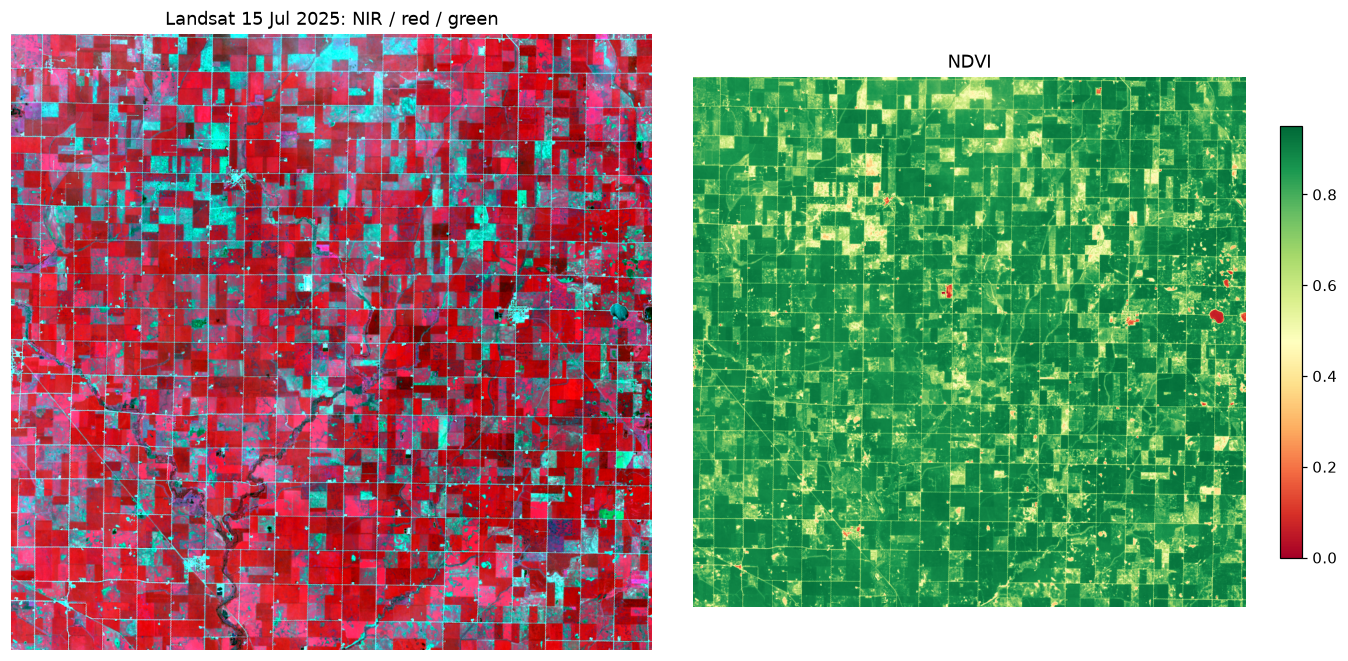

In [6]:
def stretch(da, lo=2, hi=98):  # percentile stretch for display
    # Percentile stretch to 0-1 for display
    v = da.values
    a, b = np.nanpercentile(v, [lo, hi])  # 2nd and 98th percentiles
    return np.clip((v - a) / (b - a), 0, 1)  # scale to 0-1

# NIR, red, green as RGB
false_colour = np.dstack([stretch(feat["nir"]), stretch(feat["red"]), stretch(feat["green"])])

fig, axes = plt.subplots(1, 2, figsize=(13, 6))  # two panels
axes[0].imshow(false_colour)  # false colour
axes[0].set_title("Landsat 15 Jul 2025: NIR / red / green")  # title
im = axes[1].imshow(feat["NDVI"], cmap="RdYlGn", vmin=0, vmax=0.95)  # NDVI map
axes[1].set_title("NDVI")  # title
plt.colorbar(im, ax=axes[1], shrink=0.7)  # colour bar
for ax in axes:  # every panel
    ax.axis("off")  # no axes
plt.tight_layout(); plt.show()  # arrange and draw

## CDL 2025 reference labels

The Cropland Data Layer gives one class code per 30 m pixel (it is itself a classification, trained
on farm-service-agency crop reports, so it is a *reference*, not perfect field truth).

### Align the CDL to the Landsat grid

The CDL uses NAD83 Conus Albers, the Landsat scene UTM zone 15N. `reproject_match` warps the CDL onto
exactly the Landsat pixel grid. **Nearest-neighbour** resampling is mandatory for categorical data:
bilinear interpolation would invent class codes that do not exist.


In [7]:
cdl = rs.read(CDL_PATH, masked=False).squeeze("band", drop=True)  # the 2025 CDL
# on the Landsat grid (nearest neighbour keeps the codes)
cdl = cdl.rio.reproject_match(feat["red"], resampling=Resampling.nearest)

codes, counts = np.unique(cdl.values, return_counts=True)  # CDL codes and their pixel counts
# code -> class name
legend = pd.read_csv(DATA / "CDL" / "30_m" / "cdl_class_legend.csv").set_index("code")["class_name"]
top = pd.DataFrame({"code": codes, "name": legend.reindex(codes).values, "pixels": counts})  # one row per code
top.sort_values("pixels", ascending=False).head(10).reset_index(drop=True)  # the ten most common classes

,code,name,pixels
0,1,Corn,514004
1,5,Soybeans,355566
2,176,Grassland/Pasture,38551
3,121,Developed/Open Space,22777
4,122,Developed/Low Intensity,17842
5,195,Herbaceous Wetlands,8943
6,190,Woody Wetlands,4814
7,0,Background,4679
8,123,Developed/Med Intensity,3033
9,37,Other Hay/Non Alfalfa,2234


### Group CDL codes into five classes

The CDL has more than 100 codes, but a handful cover almost all of this AOI. They are grouped into five
classes: **Corn, Soybeans, Developed** (all intensity levels), **Grass/Pasture** and **Forest/Wetland**
(forest types plus woody and herbaceous wetlands, which are spectrally and ecologically similar).
Open water (about 0.2 % of the area) and the many minor crops are left out (`-1`): classes this
small have too few pixels for a reliable train/validation/test split, and forcing them into another
class would corrupt the labels. Cloudy or shadowed
pixels from the QA mask are also set to `-1`. The result is `labels`, an integer raster on the image grid
that follows the GeoLattice convention (`attrs["nodata"] = -1`).


In [8]:
# the five task classes and their CDL codes
GROUPS = {"Corn": [1], "Soybeans": [5], "Developed": [121, 122, 123, 124], "Grass/Pasture": [176],
          "Forest/Wetland": [141, 142, 143, 190, 195]}
CLASS_NAMES = list(GROUPS)  # class names
CLASS_IDS = list(range(len(CLASS_NAMES)))  # class ids 0-4
COLORS = ["#ffd300", "#267000", "#999999", "#e8ffbf", "#4f9a7a"]
CMAP = ListedColormap(COLORS)  # colour map of the classes
names_by_id = dict(enumerate(CLASS_NAMES))  # id -> name

lab = np.full(cdl.shape, -1, dtype="int32")  # -1 = no label
for i, group_codes in enumerate(GROUPS.values()):  # each class ...
    lab[np.isin(cdl.values, group_codes)] = i  # ... gets its id where the CDL code matches
lab[~clear.values] = -1                         # drop cloud / shadow pixels

labels = cdl.copy(data=lab).rename("labels")  # as a DataArray on the Landsat grid
labels.attrs["nodata"] = -1  # record the no-data value
# labelled pixels per class
pd.Series(np.bincount(lab[lab >= 0], minlength=len(CLASS_NAMES)), index=CLASS_NAMES, name="pixels").to_frame()

,pixels
Corn,501337
Soybeans,349351
Developed,43207
Grass/Pasture,37906
Forest/Wetland,15036


### View the labels

Corn and soybeans cover about 90 % of the labelled area, so the problem is strongly imbalanced: developed
land, pasture and forest/wetland have far fewer pixels. This is why the notebook reports **macro F1** (the unweighted mean of
per-class F1) and per-class scores, not just overall accuracy.


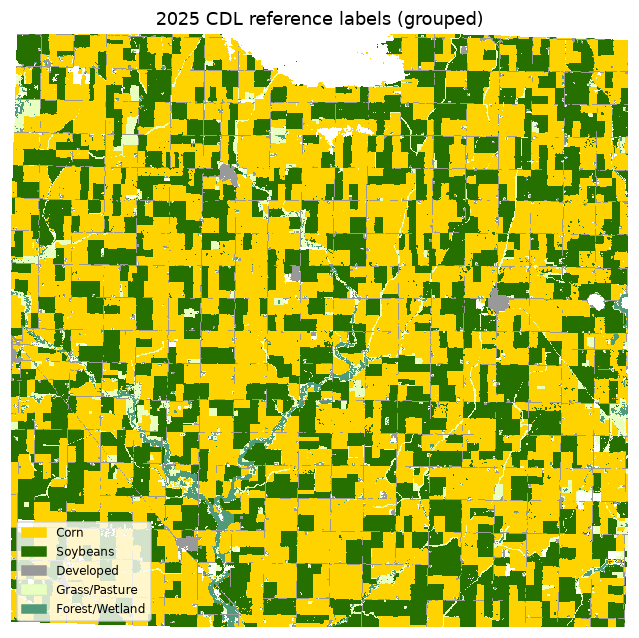

In [9]:
fig, ax = plt.subplots(figsize=(8, 7))  # one panel
# the label map
ax.imshow(np.ma.masked_less(lab, 0), cmap=CMAP, vmin=-0.5, vmax=len(CLASS_NAMES) - 0.5, interpolation="nearest")
ax.legend(handles=[Patch(color=c, label=n) for c, n in zip(COLORS, CLASS_NAMES)],  # class legend
          loc="lower left", fontsize=8, frameon=True)
ax.set_title("2025 CDL reference labels (grouped)")  # title
ax.axis("off"); plt.show()  # no axes, draw

## Train / validation / test split

Neighbouring pixels in a field are almost identical. A *random* pixel split puts near-duplicates in
both the training and test sets and inflates accuracy. GeoLattice therefore splits by **geography**: the
area is cut into square blocks and whole blocks are assigned to one set.

- **Train (60 %)**: fits the models.
- **Validation (20 %)**: compares models and tunes choices.
- **Test (20 %)**: used **once**, at the end, to report accuracy.

### Sample every labelled pixel

`ic.sample_pixels(feat, labels)` returns the feature table `X`, the label vector `y` and the map
coordinates of each pixel (`coords`), dropping any pixel with a missing predictor.
`ic.spatial_block_split` then assigns blocks of **1.5 km** (50 pixels) to train, validation and test.
`stratify=y` tries several block shuffles and keeps the one where each set covers the most classes.
`ic.check_split_isolation` confirms that no pixel is in two sets.


In [10]:
X, y, coords = ic.sample_pixels(feat, labels)  # features, labels and coordinates of every labelled pixel
BLOCK = 1500          # metres; larger than the typical field size
# 60 / 20 / 20 split by 1.5 km blocks, class-balanced
sp = ic.spatial_block_split(coords, block_size=BLOCK, test_size=0.2, val_size=0.2, seed=SEED, stratify=y)
ic.check_split_isolation(train=sp.train, val=sp.val, test=sp.test)  # no pixel in two splits

split_table = pd.DataFrame({name: np.bincount(y[idx], minlength=len(CLASS_NAMES))  # pixels per class and split
                            for name, idx in [("train", sp.train), ("validation", sp.val), ("test", sp.test)]},
                           index=CLASS_NAMES)
split_table.loc["Total"] = split_table.sum()  # totals
split_table  # show the table

,train,validation,test
Corn,300906,100525,99905
Soybeans,206612,75778,66961
Developed,26903,8799,7505
Grass/Pasture,23237,6884,7785
Forest/Wetland,11070,2099,1867
Total,568728,194085,184023


### Map the blocks

`spl` is a raster holding `0` (train), `1` (validation) or `2` (test) at each sampled pixel. To place the
pixels back on the grid, the coordinates are converted into row and column indices (`ix`, `iy`). The
map shows that each set is made of contiguous blocks. `spl` is reused for OBIA in the *Object-based classification (OBIA)* section.


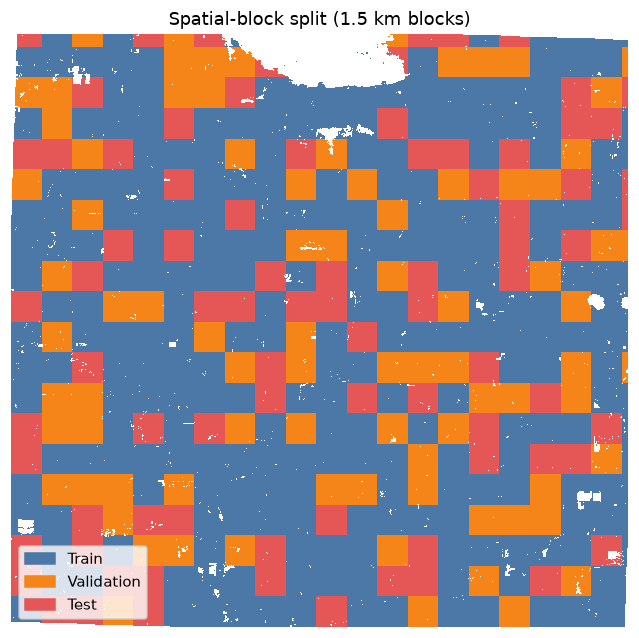

In [11]:
# Row/column of each sampled pixel on the raster grid
ix = np.searchsorted(feat.x.values, coords[:, 0])
iy = np.searchsorted(-feat.y.values, -coords[:, 1])  # row of each sampled pixel

spl = np.full(lab.shape, -1, dtype="int8")  # -1 = not sampled
for k, idx in enumerate([sp.train, sp.val, sp.test]):  # each split ...
    spl[iy[idx], ix[idx]] = k  # ... written as 0, 1 or 2

fig, ax = plt.subplots(figsize=(8, 7))  # one panel
ax.imshow(np.ma.masked_less(spl, 0), cmap=ListedColormap(["#4c78a8", "#f58518", "#e45756"]),
          vmin=-0.5, vmax=2.5, interpolation="nearest")
ax.legend(handles=[Patch(color=c, label=n) for c, n in  # legend
                   zip(["#4c78a8", "#f58518", "#e45756"], ["Train", "Validation", "Test"])], loc="lower left")
ax.set_title("Spatial-block split (1.5 km blocks)"); ax.axis("off"); plt.show()  # title, no axes, draw

### Draw the working samples

Fitting an SVM on 560,000 pixels would take hours and adds little accuracy, so the models are
trained on a **class-balanced sample** of up to 3,000 pixels per class from the training blocks. The
validation and test sets are **random samples with natural class proportions** (20,000 and 30,000
pixels): they must reflect the real class mix to give honest accuracy figures.


In [12]:
rng = np.random.default_rng(SEED)  # random generator

def cap_per_class(idx, n):  # a capped, class-balanced subset of the indices idx
    # Up to n random pixels from each class in idx
    picks = [rng.choice(idx[y[idx] == c], min(n, int((y[idx] == c).sum())), replace=False)
             for c in CLASS_IDS if (y[idx] == c).any()]
    return np.concatenate(picks)  # all picks together

tr = cap_per_class(sp.train, 3000)                       # balanced training sample
va = rng.choice(sp.val, 20_000, replace=False)           # natural proportions
te = rng.choice(sp.test, 30_000, replace=False)          # natural proportions
print("train:", len(tr), "| validation:", len(va), "| test:", len(te))  # sample sizes

train: 15000 | validation: 20000 | test: 30000


## Pixel-based classification

All four methods see the same eight predictors for each pixel. Results are scored with a helper that
wraps `ic.classification_report`, which returns overall accuracy, Cohen's kappa, macro F1, per-class
precision/recall/F1 and the confusion matrix.


In [13]:
def evaluate(y_true, y_pred):  # accuracy report with class names
    # Full GeoLattice report with readable class names
    return ic.classification_report(y_true, y_pred, labels=CLASS_IDS, class_names=names_by_id)

def summary_row(name, report):  # the three headline scores of a report
    # overall accuracy, kappa and macro F1
    return {"Model": name, "Overall accuracy": report["overall_accuracy"],
            "Kappa": report["kappa"], "Macro F1": report["macro_f1"]}

### Unsupervised: k-means

`ic.unsupervised_classify` z-scores the predictors, fits k-means on a random sample of image pixels
and labels every pixel with its cluster. No labels are used, so the clusters are only *spectral* groups.
We ask for **12 clusters**, more than the 5 classes, because one land-cover class often spans several
spectral clusters (for example early and late-planted soybeans). Each cluster is then **named** by the
class that dominates it among the *training* pixels. This is the analyst's step, automated, and it uses
no validation or test labels.


In [14]:
# Fit k-means on image spectra only (no labels involved)
cluster_map, km = ic.unsupervised_classify(feat, n_classes=12, seed=SEED)

def cluster_ids(idx):  # cluster id of the sampled pixels idx
    # Cluster of each sampled pixel, using the fitted scaler and k-means model
    return km.predict(km.normalizer_.transform(X.to_numpy()[idx]))

# Name each cluster by its majority training class
crosstab = pd.crosstab(cluster_ids(tr), y[tr])
cluster_to_class = crosstab.idxmax(axis=1).to_dict()  # cluster -> its most common training class
# class and training pixels of every cluster
cluster_names = pd.DataFrame({"class": [CLASS_NAMES[c] for c in cluster_to_class.values()],
                              "training pixels": crosstab.sum(axis=1)}, index=crosstab.index)
cluster_names.index.name = "cluster"  # index name
cluster_names.T  # one column per cluster

cluster,0,1,2,3,4,5,6,7,8,9,10,11
class,Corn,Developed,Soybeans,Soybeans,Soybeans,Corn,Developed,Soybeans,Forest/Wetland,Forest/Wetland,Grass/Pasture,Developed
training pixels,1461,1346,1250,405,2050,1130,61,1140,2480,91,3409,177


### Supervised: Random Forest, SVM and XGBoost

`ic.train_pixel_classifier` fits a supervised model by name (`"rf"`, `"svm"` or `"xgb"`):

- **Random Forest**: many decision trees on bootstrap samples; robust, little tuning, gives feature
  importance.
- **SVM** (RBF kernel): finds a smooth maximum-margin boundary. It is sensitive to feature scale; all
  eight predictors here lie roughly between -1 and 1 and `gamma="scale"` adapts to their variance.
  `C` controls how strictly training errors are penalised. `probability=False` skips the slow
  probability calibration, which is not needed for class labels.
- **XGBoost**: boosted trees built one after another, each correcting the previous errors.

Passing `coords` and `block_size` also returns a **spatial cross-validation** table (three folds of
whole 1.5 km blocks inside the training data), an estimate of generalisation before the validation set is
touched.


In [15]:
PARAMS = {  # settings of the three classifiers
    "rf":  dict(n_estimators=300, n_jobs=-1),
    "svm": dict(C=10, kernel="rbf", gamma="scale", probability=False),
    "xgb": dict(n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.8,
                colsample_bytree=0.8, n_jobs=-1, random_state=SEED),
}
LABELS = {"rf": "Random Forest", "svm": "SVM", "xgb": "XGBoost"}  # display names

models, cv_tables = {}, {}  # fitted models and cross-validation tables
for key, params in PARAMS.items():  # each classifier
    # fit on the training sample, 3-fold spatial CV inside it
    models[key], cv_tables[key] = ic.train_pixel_classifier(
        X.iloc[tr], y[tr], model=key, coords=coords[tr], block_size=BLOCK, n_splits=3,
        seed=SEED, **params)

# mean cross-validation scores
pd.DataFrame({LABELS[k]: t[["accuracy", "macro_f1", "kappa"]].mean() for k, t in cv_tables.items()}).T.round(3)

,accuracy,macro_f1,kappa
Random Forest,0.787,0.785,0.734
SVM,0.774,0.772,0.717
XGBoost,0.791,0.789,0.738


### Compare the methods on the validation set

Each method predicts the 20,000 validation pixels. Accuracy is high for all models because corn and
soybeans dominate, so **macro F1** is the main criterion for choosing a model: it treats a rare class
such as forest or water as important as corn.


In [16]:
# k-means clusters translated to classes
val_pred = {"K-means": np.array([cluster_to_class[c] for c in cluster_ids(va)])}
for key, model in models.items():  # each supervised model
    val_pred[LABELS[key]] = model.predict(X.iloc[va])  # its validation predictions

val_reports = {name: evaluate(y[va], p) for name, p in val_pred.items()}  # report of each model
val_table = (pd.DataFrame([summary_row(n, r) for n, r in val_reports.items()])  # scores sorted by macro F1
             .set_index("Model").sort_values("Macro F1", ascending=False).round(3))
val_table  # show them

,Overall accuracy,Kappa,Macro F1
Model,,,
XGBoost,0.859,0.774,0.641
Random Forest,0.855,0.768,0.636
SVM,0.834,0.739,0.630
K-means,0.737,0.601,0.508


Per-class F1 on the validation set shows where each method struggles. Corn and soybeans differ only
slightly in July spectra and are the main source of confusion; small classes (forest/wetland, developed) are the
hardest because they have few training pixels.


In [17]:
pd.DataFrame({n: r["per_class"]["f1"] for n, r in val_reports.items()}).round(2)  # per-class F1 of every model

,K-means,Random Forest,SVM,XGBoost
Corn,0.81,0.89,0.86,0.90
Soybeans,0.87,0.95,0.96,0.95
Developed,0.48,0.65,0.65,0.64
Grass/Pasture,0.30,0.54,0.56,0.56
Forest/Wetland,0.07,0.15,0.11,0.16


## Final evaluation and map

The best supervised pixel model by **validation macro F1** is scored once on the **test** blocks. No
model was fitted or selected using these pixels. Overall accuracy, kappa and per-class metrics
are the numbers to report.


In [18]:
# validation macro F1 of the supervised models
supervised_val = {k: val_reports[LABELS[k]]["macro_f1"] for k in models}
best_key = max(supervised_val, key=supervised_val.get)  # the best of them
best_pixel_model = models[best_key]  # its fitted model
print("Selected on validation macro F1:", LABELS[best_key])  # report the choice

test_pred_pixel = best_pixel_model.predict(X.iloc[te])  # predict the test pixels once
test_report = evaluate(y[te], test_pred_pixel)  # test report
print(f"Test overall accuracy {test_report['overall_accuracy']:.3f} | "  # headline scores
      f"kappa {test_report['kappa']:.3f} | macro F1 {test_report['macro_f1']:.3f}")
test_report["per_class"].round(3)  # per-class scores

Selected on validation macro F1: XGBoost
Test overall accuracy 0.860 | kappa 0.773 | macro F1 0.646


,precision,recall,f1,support
Corn,0.986,0.838,0.906,16356
Soybeans,0.971,0.923,0.946,10901
Developed,0.488,0.806,0.608,1155
Grass/Pasture,0.547,0.735,0.628,1265
Forest/Wetland,0.082,0.545,0.143,323


The confusion matrix shows, row by row, how the CDL (reference) pixels were classified. The diagonal
is correct; the off-diagonal cells reveal systematic confusion (usually corn vs. soybeans, and developed
land vs. grass or forest/wetland).


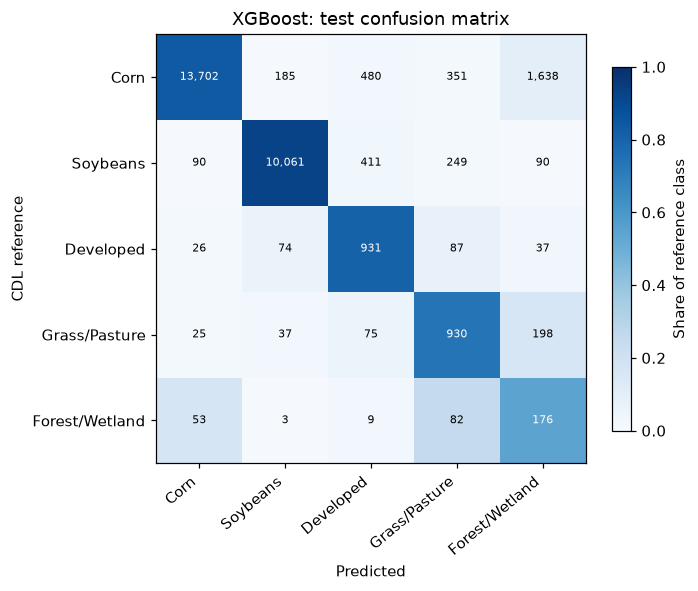

In [19]:
cm = test_report["confusion_matrix"]  # test confusion matrix
fig, ax = plt.subplots(figsize=(6.5, 5.5))  # one panel
norm = cm.div(cm.sum(axis=1), axis=0)                      # row-normalised: recall per class
im = ax.imshow(norm.values, cmap="Blues", vmin=0, vmax=1)  # shares as colours
ax.set_xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=40, ha="right")  # predicted classes on x
ax.set_yticks(range(len(CLASS_NAMES)), CLASS_NAMES)  # reference classes on y
for (r, c), v in np.ndenumerate(cm.values):  # every cell ...
    ax.text(c, r, f"{int(v):,}", ha="center", va="center", fontsize=7,  # ... with its count
            color="white" if norm.values[r, c] > 0.5 else "black")
ax.set_xlabel("Predicted"); ax.set_ylabel("CDL reference")  # axis labels
ax.set_title(f"{LABELS[best_key]}: test confusion matrix")  # title
plt.colorbar(im, ax=ax, shrink=0.8, label="Share of reference class")  # colour bar
plt.tight_layout(); plt.show()  # arrange and draw

### Map the whole scene

`ic.predict_map` applies the fitted model to every valid pixel in `feat` and returns a class raster
(`-1` where predictors are missing). It is shown beside the CDL reference. The pixel map is
"salt-and-pepper" noisy inside fields, a typical limitation of pixel-based classification that OBIA
addresses in the next section.


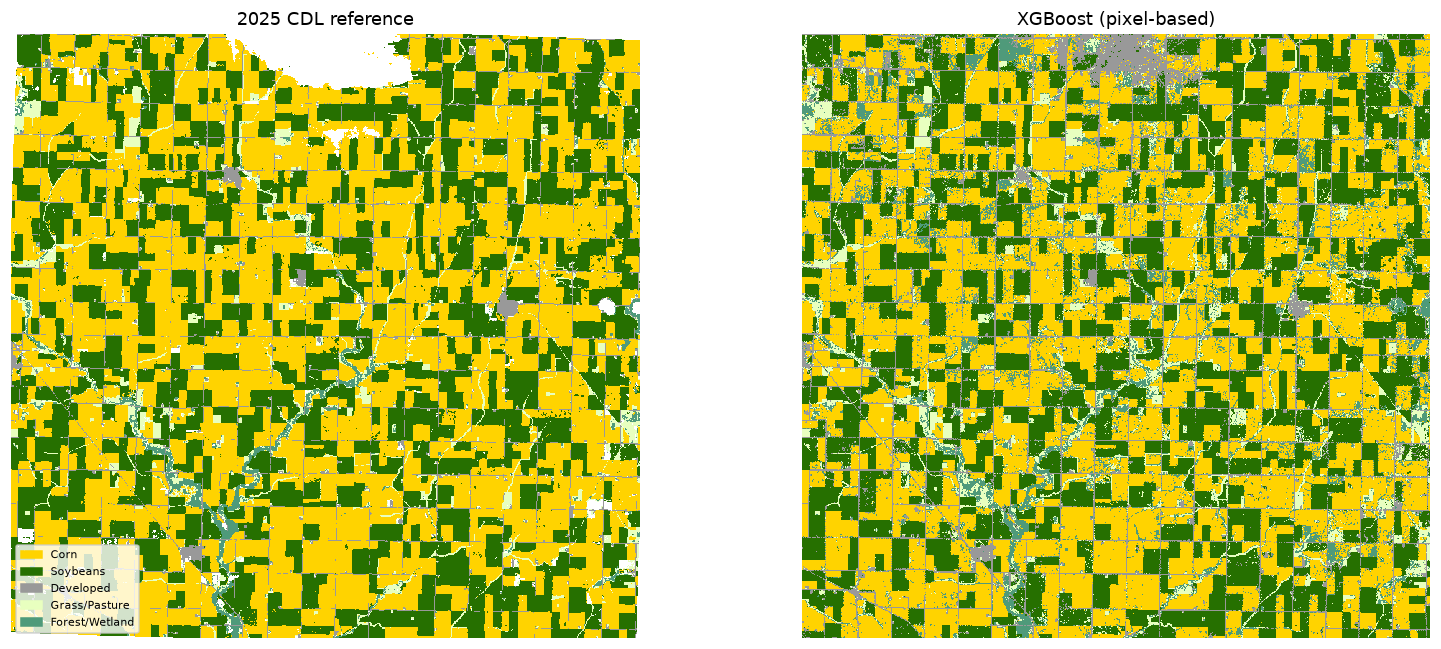

In [20]:
pixel_map = ic.predict_map(best_pixel_model, feat)  # classify every pixel with the selected model

def show_maps(maps, titles, size=(15, 6)):  # draw class maps side by side
    fig, axes = plt.subplots(1, len(maps), figsize=size)  # one panel per map
    for ax, m, t in zip(np.atleast_1d(axes), maps, titles):  # each map
        # masked class map with the shared colours
        ax.imshow(np.ma.masked_less(np.asarray(m), 0), cmap=CMAP, vmin=-0.5,
                  vmax=len(CLASS_NAMES) - 0.5, interpolation="nearest")
        ax.set_title(t); ax.axis("off")  # title, no axes
    # class legend on the first panel
    np.atleast_1d(axes)[0].legend(handles=[Patch(color=c, label=n) for c, n in zip(COLORS, CLASS_NAMES)],
                                  loc="lower left", fontsize=7)
    plt.tight_layout(); plt.show()  # arrange and draw

# reference and prediction
show_maps([lab, pixel_map.values], ["2025 CDL reference", f"{LABELS[best_key]} (pixel-based)"])

### Random Forest feature importance

Impurity-based importance shows which predictors the forest relied on most. It is a quick diagnostic,
not a causal explanation, and can favour correlated predictors (the SWIR bands and NDMI are related).


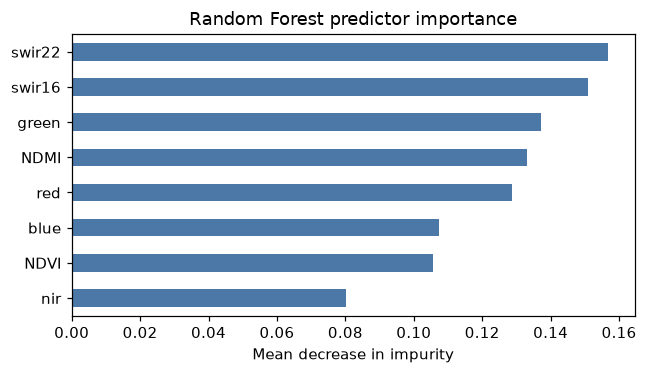

In [21]:
rf_model = models["rf"].model              # underlying scikit-learn forest
# importance of each predictor, smallest first
importance = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values()
importance.plot.barh(figsize=(6, 3.5), color="#4c78a8")
plt.xlabel("Mean decrease in impurity"); plt.title("Random Forest predictor importance")  # label and title
plt.tight_layout(); plt.show()  # arrange and draw

## Object-based classification (OBIA)

Pixel classification ignores the neighbourhood. **OBIA** first groups pixels into homogeneous
regions (objects) and classifies each object from the *statistics of its pixels* plus its *shape*. In
farmland, objects follow field boundaries, so labels become smooth and the noise inside fields disappears.

### Segment the image

`obia.segment` runs **SLIC** (simple linear iterative clustering): it min-max scales the bands and
grows compact superpixels of similar spectra. `n_segments=25000` asks for objects of about 40 pixels
(roughly 3.6 ha), smaller than a typical field so that most objects lie inside one field, and small enough to fit towns and woodlots.
`compactness` balances spectral similarity against compact shape: lower values follow field
edges more closely. Pixels with missing data get segment id `0`. This step takes a few minutes.


In [22]:
# SLIC superpixels on the eight predictors
segments = obia.segment(feat, method="slic", n_segments=25_000, compactness=0.5)
print(f"{int(segments.max()):,} segments | median size "  # number and median size of the segments
      f"{int(np.median(np.bincount(segments.values[segments.values > 0]))):,} pixels")

24,593 segments | median size 40 pixels


Segment boundaries are drawn on a 200 x 200 pixel window of the false-colour image. They should
follow the straight field edges of the Corn Belt.


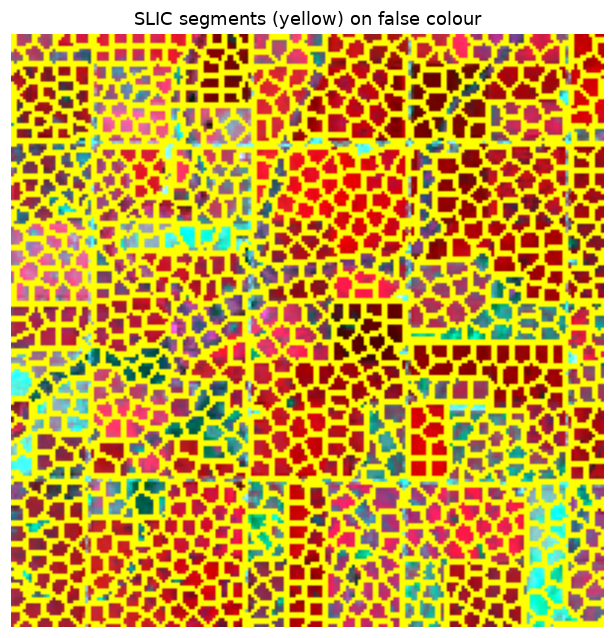

In [23]:
r0, c0, size = 450, 500, 200                     # window origin and size (pixels)
window = (slice(r0, r0 + size), slice(c0, c0 + size))  # row and column slices of the window
plt.figure(figsize=(7, 7))  # one figure
# segment outlines on the false-colour image
plt.imshow(mark_boundaries(false_colour[window], segments.values[window], color=(1, 1, 0)))
plt.title("SLIC segments (yellow) on false colour"); plt.axis("off"); plt.show()  # title, no axes, draw

### Describe each object

`obia.segment_features` computes, for each segment, the **mean and standard deviation** of every
predictor (spectral signature and within-object texture) plus **shape descriptors** (area, perimeter,
compactness). The result has one row per object.


In [24]:
object_features = obia.segment_features(feat, segments)  # per-segment statistics of every predictor
print(object_features.shape)  # segments x features
object_features.iloc[:, :6].head()  # the first six features

(24593, 19)


,blue_mean,blue_std,green_mean,green_std,red_mean,red_std
segment,,,,,,
1,0.040574,0.004572,0.071559,0.004696,0.048811,0.008724
2,0.041419,0.004391,0.075924,0.005786,0.059076,0.010156
3,0.041931,0.003996,0.074038,0.004245,0.051727,0.009425
4,0.041594,0.003354,0.075235,0.004260,0.057707,0.009278
5,0.039748,0.003331,0.071112,0.002546,0.046325,0.006918


### Label the objects and assign them to splits

An object takes the **majority CDL class** of its labelled pixels, and its **purity** is the share of
pixels in that class. The same logic assigns the object to a split by the majority of its pixels' split
ids (`spl`), so objects inherit the spatial blocks of the *Train / validation / test split* section. Only objects with a purity of at least
**70 %** are used for training and scoring: a segment covering half corn and half soybean has no single
valid label.


In [25]:
seg = segments.values  # segment id of every pixel
mask = (seg > 0) & (lab >= 0)  # pixels inside a segment and with a label
# segment, label and split of those pixels
pix = pd.DataFrame({"segment": seg[mask], "label": lab[mask], "split": spl[mask]})

class_counts = pd.crosstab(pix["segment"], pix["label"])  # label counts per segment
split_counts = pd.crosstab(pix["segment"], pix["split"])  # split counts per segment

objects = pd.DataFrame({  # one row per segment
    "label": class_counts.idxmax(axis=1),                          # majority class
    "purity": class_counts.max(axis=1) / class_counts.sum(axis=1), # share of that class
    "split": split_counts.idxmax(axis=1),                          # majority split
})
# segments at least 70 % pure and inside a split
pure = objects[(objects["purity"] >= 0.70) & (objects["split"] >= 0)]

# pure segments per class and split
pd.DataFrame({name: pure[pure["split"] == k]["label"].map(names_by_id).value_counts()
              for k, name in enumerate(["train", "validation", "test"])}).fillna(0).astype(int)

,train,validation,test
label,,,
Corn,7191,2381,2388
Soybeans,4847,1782,1600
Grass/Pasture,258,63,80
Developed,162,48,21
Forest/Wetland,158,24,7


### Train the object classifiers

Random Forest and XGBoost are fitted on training objects (using all 19 object features) and compared on
validation objects, again by macro F1. Objects are far fewer than pixels, so training is fast.


In [26]:
OBJ_X = object_features.loc[pure.index]  # features of the pure segments
# which segments are training, validation and test
tr_o, va_o, te_o = (pure["split"] == 0).values, (pure["split"] == 1).values, (pure["split"] == 2).values
obj_y = pure["label"].values  # their labels

obj_models, obj_val = {}, {}  # object models and their validation reports
for key in ["rf", "xgb"]:  # random forest and XGBoost
    # fit on the training objects
    obj_models[key], _ = ic.train_pixel_classifier(OBJ_X[tr_o], obj_y[tr_o], model=key, seed=SEED, **PARAMS[key])
    # score on the validation objects
    obj_val[key] = evaluate(obj_y[va_o], obj_models[key].predict(OBJ_X[va_o]))

best_obj_key = max(obj_val, key=lambda k: obj_val[k]["macro_f1"])  # the better object model
# its validation scores
pd.DataFrame([summary_row(f"OBIA {LABELS[k]}", r) for k, r in obj_val.items()]).set_index("Model").round(3)

,Overall accuracy,Kappa,Macro F1
Model,,,
OBIA Random Forest,0.984,0.970,0.834
OBIA XGBoost,0.988,0.977,0.862


### Predict every object and map it

The selected model predicts **all** segments (including the impure ones). `obia.segments_to_raster`
paints each object's class back onto the pixels it covers, producing a field-like thematic map.


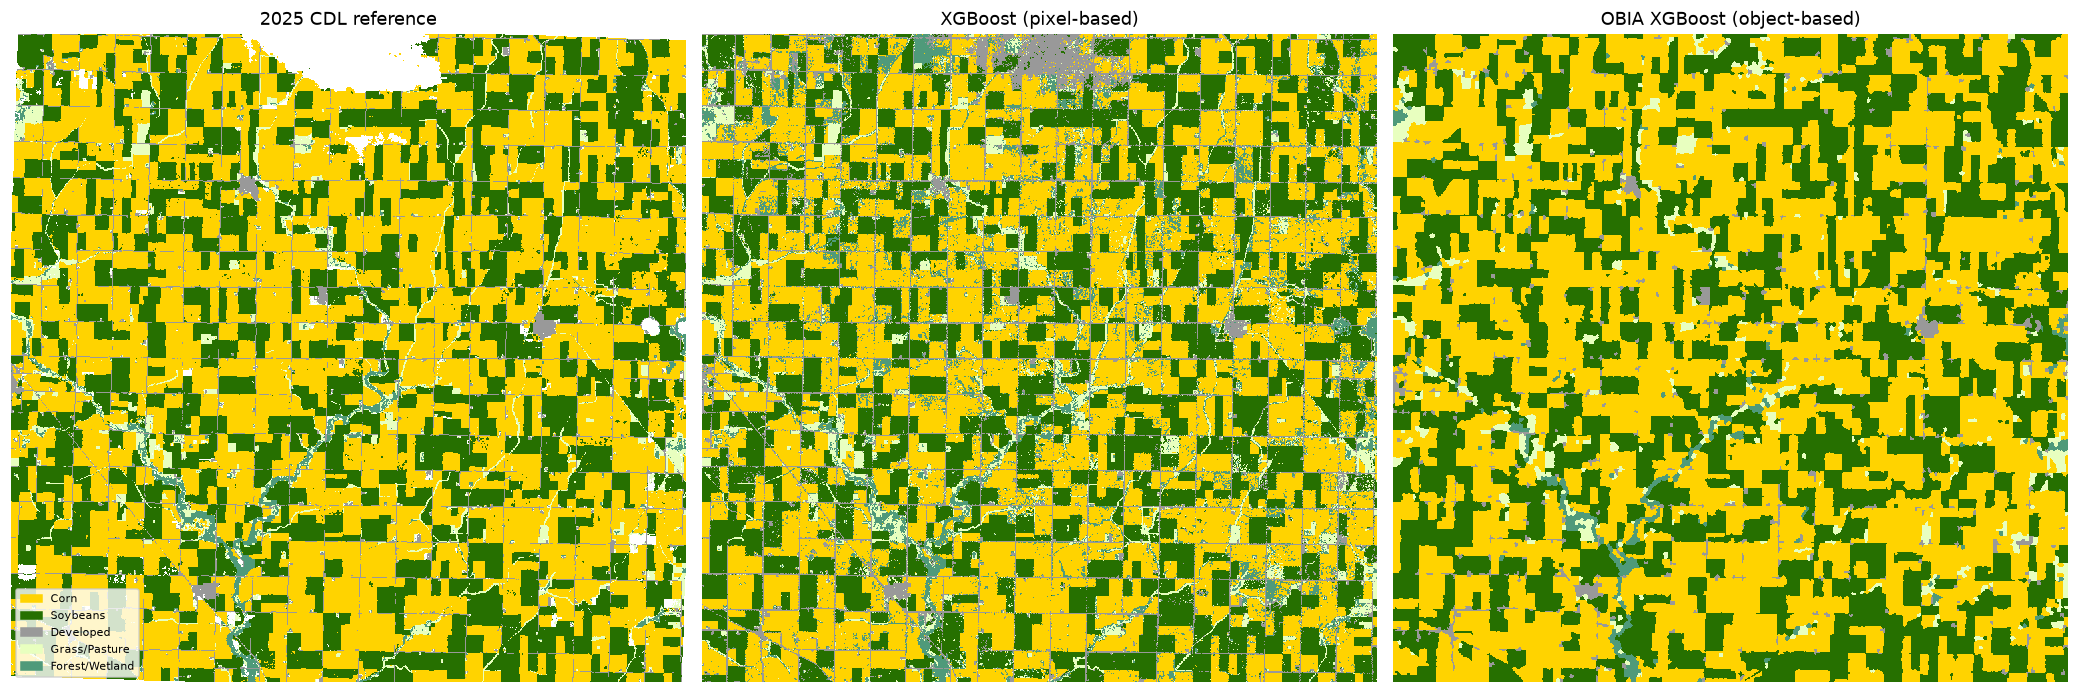

In [27]:
# classify every segment
obj_pred = pd.Series(obj_models[best_obj_key].predict(object_features), index=object_features.index, name="class")
# paint the segment classes back onto the pixels
obia_map = obia.segments_to_raster(obj_pred, segments, fill=-1)
show_maps([lab, pixel_map.values, obia_map.values],  # reference, pixel map and object map
          ["2025 CDL reference", f"{LABELS[best_key]} (pixel-based)", f"OBIA {LABELS[best_obj_key]} (object-based)"],
          size=(19, 6.5))

### Object-level test accuracy

Scoring only **test objects** (pure objects in test blocks) gives the object-level accuracy: each object
counts once, whatever its size. These numbers are *not* directly comparable with pixel accuracy, so the *Pixel vs. object comparison* section
re-scores OBIA on the same test **pixels** used for the other methods.


In [28]:
# score the test objects once
obj_test_report = evaluate(obj_y[te_o], obj_models[best_obj_key].predict(OBJ_X[te_o]))
# headline scores
print(f"Test objects: {int(te_o.sum()):,} | overall accuracy {obj_test_report['overall_accuracy']:.3f} | "
      f"kappa {obj_test_report['kappa']:.3f} | macro F1 {obj_test_report['macro_f1']:.3f}")
obj_test_report["per_class"].round(3)  # per-class scores

Test objects: 4,096 | overall accuracy 0.992 | kappa 0.984 | macro F1 0.869


,precision,recall,f1,support
Corn,0.997,0.994,0.995,2388
Soybeans,0.995,0.996,0.996,1600
Developed,0.955,1.000,0.977,21
Grass/Pasture,0.866,0.888,0.877,80
Forest/Wetland,0.444,0.571,0.500,7


## Pixel vs. object comparison

For a fair comparison every method is scored on the **same 30,000 test pixels** (`te`). For OBIA, the
object map is read at those pixel locations (`iy`, `ix`). The table lists overall accuracy, kappa and macro F1.


In [29]:
# k-means classes for the test pixels
test_pred = {"K-means": np.array([cluster_to_class[c] for c in cluster_ids(te)])}
for key, model in models.items():  # each pixel model
    test_pred[LABELS[key]] = model.predict(X.iloc[te])  # its test predictions
# object map values at the same pixels
test_pred[f"OBIA {LABELS[best_obj_key]}"] = obia_map.values[iy[te], ix[te]].astype(int)

test_reports = {n: evaluate(y[te], p) for n, p in test_pred.items()}  # report of each
final = (pd.DataFrame([summary_row(n, r) for n, r in test_reports.items()])  # scores sorted by macro F1
         .set_index("Model").sort_values("Macro F1", ascending=False).round(3))
final  # show them

,Overall accuracy,Kappa,Macro F1
Model,,,
XGBoost,0.860,0.773,0.646
Random Forest,0.857,0.769,0.644
SVM,0.834,0.737,0.633
OBIA XGBoost,0.903,0.823,0.586
K-means,0.751,0.615,0.513


In [30]:
f1 = pd.DataFrame({n: r["per_class"]["f1"] for n, r in test_reports.items()})  # per-class F1 of every method
f1.round(2)  # show it

,K-means,Random Forest,SVM,XGBoost,OBIA XGBoost
Corn,0.83,0.90,0.87,0.91,0.95
Soybeans,0.88,0.95,0.95,0.95,0.92
Developed,0.46,0.63,0.63,0.61,0.28
Grass/Pasture,0.34,0.62,0.62,0.63,0.52
Forest/Wetland,0.06,0.13,0.10,0.14,0.25


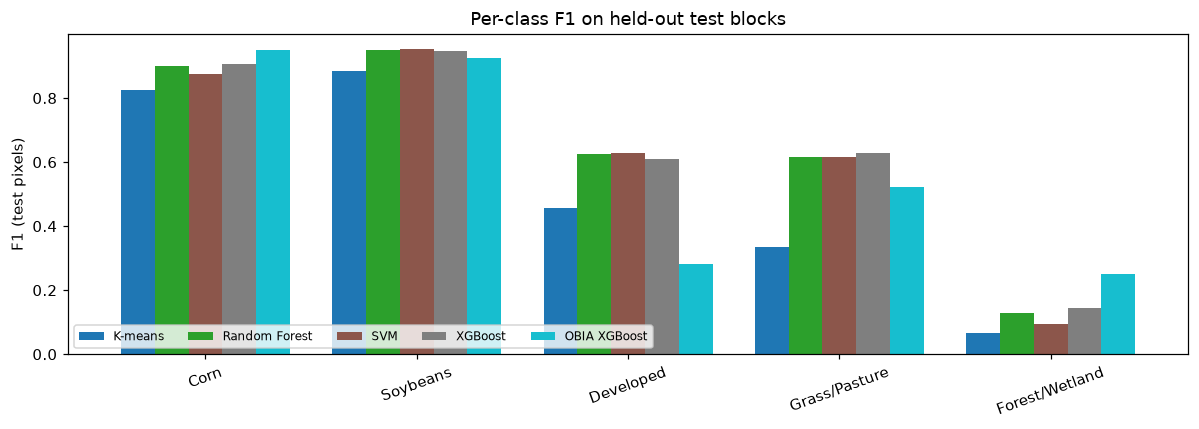

In [31]:
f1.plot.bar(figsize=(11, 4), width=0.8, colormap="tab10")  # grouped bar chart
plt.ylabel("F1 (test pixels)"); plt.title("Per-class F1 on held-out test blocks")  # label and title
plt.legend(fontsize=8, ncol=5, loc="lower left"); plt.xticks(rotation=20)  # legend and tick labels
plt.tight_layout(); plt.show()  # arrange and draw

## Summary and exercises

**What we did.** A single mid-season Landsat scene (six bands plus NDVI and NDMI) was classified into
five land-cover classes using the 2025 CDL as labels. Labels were split into train/validation/test
sets by **spatial blocks**; models were compared on validation data and every method was scored once on the
held-out **test** pixels.

**Reading the results.**

- **K-means** needs no labels but its clusters only loosely match classes; it is the lowest baseline.
- **Random Forest and XGBoost** are accurate, fast and robust; **SVM** is competitive but scales poorly
  with the number of samples (the reason for the capped training sample).
- **OBIA** removes the pixel-level noise and respects field boundaries, but its accuracy depends on the
  segmentation scale: segments that straddle two fields (impure objects) cannot be labelled correctly.
- **Class balance matters.** The pixel models were trained on a class-balanced sample but tested on natural proportions, so they
  find most rare-class pixels (high recall) at the price of many false alarms (low precision for forest/wetland). The OBIA
  models were trained on natural object proportions: higher overall accuracy, but they miss more rare-class pixels. Choose the
  balance that matches the application.
- Corn vs. soybeans is the hardest pair on a **single date**; the main gain comes from adding dates
  (spring and autumn scenes capture planting and senescence differences).

**Caveats.**

- The CDL is itself a model-based product (typically 90-95 % accurate for corn and soybeans) and not field
  survey truth; accuracies here measure agreement with the CDL.
- Spatial blocking reduces, but does not eliminate, optimism: the test blocks are in the same AOI and
  year as the training blocks. Transfer to other regions or years needs additional validation.
- An object that straddles a block boundary is assigned to the split of the majority of its pixels.
- Test numbers depend on the random seed and block layout; vary `SEED` and `BLOCK` to see their spread.

### Exercises

1. Add more predictors (e.g. `ls.rs.index(["SAVI", "EVI", "MNDWI"])`) and see whether macro F1 improves.
2. Change `BLOCK` to 500 m and 5,000 m. How do spatial CV and test accuracy change?
3. Tune `C` and `gamma` for the SVM, and `max_depth` / `learning_rate` for XGBoost, using **only** the
   validation set.
4. Change `n_segments` (e.g. 4,000 and 30,000) and `compactness`; plot object purity against scale.
5. Add the 4 May 2025 Landsat 9 scene (`2025_05_LC09_...`) and the 3 October scene as extra predictors
   and quantify how much a multi-date stack improves corn vs. soybean separation.
6. Rerun with the CDL of 2023 and the 2023 Landsat 9 scenes to test how well a model trained in one year
   transfers to another (a temporal split).
